
# 1. simulazioni esponenziali per tempi di vita

In [1]:
import numpy as np
import pandas as pd
from itertools import cycle
from matplotlib.path import Path as MplPath
import tifffile
import sys
from pathlib import Path
import plotly.graph_objects as go
from phasorpy.plot import PhasorPlot     # phasor plot stolen from phasorpy 

# librerie personali (da sistemare perché fanno schifo)
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost

import lib.randgen
import lib.my_stats

<h3> Data generation

In [2]:
# estimate of tau 

τ_true = 4.0 # ns
N_evt = 500

tempi = np.random.exponential(scale = τ_true, size=N_evt)
n, xe = np.histogram(tempi, bins='auto')   
    # I'm saving the data in a histogram to use it later for the chi-square test
    # xe = bin edges, n = bin heights


<h3> Method 1: Tau as arithmetical average of the data set

In [3]:
τ_fit = np.mean(tempi)
τ_err = τ_fit / np.sqrt(N_evt)    # see bottom of paragraph for explanation of the error calculation
print(f"Analytical result: tau = {τ_fit:.3f} ± {τ_err:.3f} ns")

print('\n')
E_i = N_evt * (np.exp(-xe[:-1]/τ_fit) - np.exp(-xe[1:]/τ_fit))
chi2 = np.sum((n - E_i)**2 / E_i)
ndof = len(n) - 1
chi2_red = chi2 / ndof
p_value = 1 - stats.chi2.cdf(chi2, ndof)  

print(f"Chi-squared: {chi2:.3f}")
print(f"Reduced Chi-squared: {chi2_red:.3f}")
print(f"dof: {ndof}")  # number of events minus number of fitted parameters per bin
print(f"pval: {p_value:.3f}")


# I am using tau_fit as the mean of the exponential distribution, which is the maximum likelihood estimator for tau. Using std(tau_fit) would not be accurate
# because it would measure std on the data, thus fluctuating with the events.

Analytical result: tau = 3.855 ± 0.172 ns


Chi-squared: 32.310
Reduced Chi-squared: 1.292
dof: 25
pval: 0.149


<h3> Method 2: Tau as parameter from exponential fit


needed because first method is only good for a pure exponential and I may need to add noise in the future

In [4]:
# CDF F(t) = 1 - e^(-t/tau)
# not using scipy version because I want tau as a parameter
def expon_cdf(x, A, τ):
    return A * τ * (1.0 - np.exp(-x / τ))   # I need cdf for the binned likelihood 


#fixing crazy chi squared results
A_guess, tau_guess = n[0], np.mean(tempi)

c_binned = cost.ExtendedBinnedNLL(n, xe, expon_cdf)
m = Minuit(c_binned, A = A_guess, τ = tau_guess)
m.limits["τ"], m.limits["A"] = (0.001, None), (0.001, None)     # placing lower limits on both parameters to avoid negative values
m.migrad()

print("\n--- Binned Likelihood Fit ---")
# if i dont leave an empty line, params will not display for some reason
display(m.params)

print("\n--- Fit Statistics ---")
lib.my_stats.minuit_stats(m)


--- Binned Likelihood Fit ---


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,A,130,8,,,0.001,,
1,τ,3.85,0.18,,,0.001,,



--- Fit Statistics ---
chi-squared: 30.12
reduced chi-squared: 1.25
dof: 24.00
p-value: 0.18


<h3> Alternative data plot for method 2

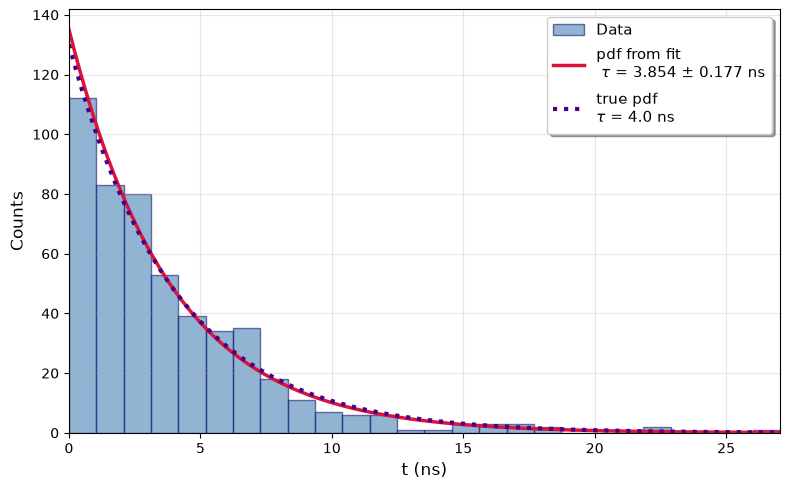

In [5]:
plt.figure(figsize=(8, 5))

# histogram
plt.hist(tempi, bins=xe, density=False, alpha=0.6, color='steelblue', 
         edgecolor='midnightblue', label='Data')                          #leaving all the details of the histogram so I can copy from here

# fitted pdf + true pdf
x_plot = np.linspace(0, xe[-1], 500)
bin_width = xe[1] - xe[0]
pdf_fit = m.values["A"] * np.exp(-x_plot / m.values["τ"]) * bin_width
pdf_true = (N_evt / τ_true) * np.exp(-x_plot / τ_true) * bin_width

plt.plot(x_plot, pdf_fit, color='crimson', linewidth=2.5, 
         label=f'pdf from fit\n $ \\tau$ = {m.values["τ"]:.3f} $\\pm$ {m.errors["τ"]:.3f} ns')
plt.plot(x_plot, pdf_true, color='indigo', linestyle='dotted', linewidth=3, 
         label=f'true pdf\n$\\tau$ = {τ_true:.1f} ns')

# cosmetics
plt.xlabel("t (ns)", fontsize=12)
plt.ylabel("Counts", fontsize=12)
plt.legend(fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3)
plt.xlim(0, xe[-1])

plt.tight_layout()
plt.show()

<h3> Method 3: unbinned log-likelihood

In [6]:
def expon_pdf(x, A, τ):
    norm = A * τ
    return norm, A * np.exp(-x / τ)


c_unbinned = cost.ExtendedUnbinnedNLL(tempi, expon_pdf)

m1 = Minuit(c_unbinned, A = A_guess, τ = tau_guess)
m1.limits["τ"], m1.limits["A"]  = (0.001, None), (0.001, None)
m1.migrad()

print("\n--- Unbinned Likelihood Fit ---")
display(m1.params)

print("\n--- Fit Statistics (to be added) ---")


--- Unbinned Likelihood Fit ---


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,A,130,8,,,0.001,,
1,τ,3.86,0.17,,,0.001,,



--- Fit Statistics (to be added) ---


# 2. FFT

Prendo 

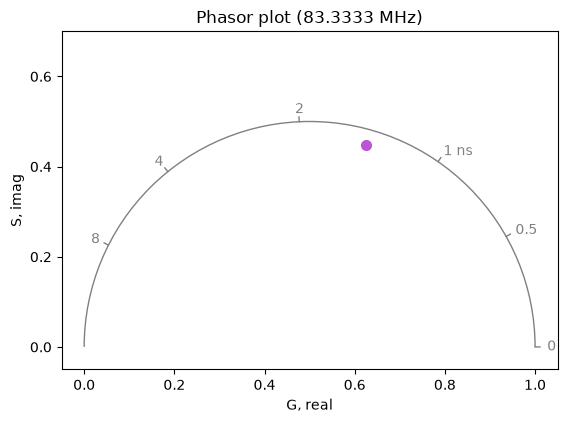

In [7]:
T_laser = 12.0  # ns
ω_laser = 1000.0 / T_laser  # MHz (83.33 MHz)

dt = xe[1] - xe[0]  # width of each bin (time resolution)
N_bins = len(n)

fft_vals = np.fft.fft(n)   # calculating FFT of the histogram data (pulls out fourier coefficients)
fft_normalised = fft_vals / fft_vals[0]    # normalization = division by the first harmonic

harm_n = 1  # harmonic number
G = np.real(fft_normalised[harm_n])
S = -np.imag(fft_normalised[harm_n])

ω = np.fft.fftfreq(N_bins, d = dt)        # extracting frequencies corresponding to the FFT bins
freq_plot = ω[harm_n]

# plotting on the semicircle
plot = PhasorPlot(frequency = ω_laser)

# Plottiamo il nostro singolo punto (G, S)
plot.plot(G, S, marker = 'o', markersize = 7, color = 'mediumorchid')

plot.show()